### 📌 Project Introduction & Dataset Justification

**Why This Problem Matters:**
Credit risk assessment is a foundational function in the financial sector. Accurately predicting whether a loan applicant is creditworthy allows lending institutions to minimize default risk, optimize interest rates, and expand financial access safely.

**Dataset Selection & Attribution:**
* **Dataset Source:** [Credit Default Dataset via ApnaClassroom GitHub Repository](https://github.com/ApnaClassroom/Dataset/blob/main/Credit%20Default.csv)
* **Dataset Owner/Host:** Hosted publicly via ApnaClassroom datasets.

**Why This Dataset Was Selected:**
* **Core Financial Indicators:** The dataset captures essential lending metrics—including **Income**, **Age**, **Loan amount**, and the derived **Loan to Income** ratio. These features directly mirror the real-world underwriting variables used by commercial banks and fintech lenders.
* **Class Imbalance Realism:** Financial datasets naturally exhibit class imbalance (where non-defaults vastly outnumber high-risk defaults). This dataset provides a realistic distribution, allowing us to implement and test specialized techniques such as stratified train-test splits and `class_weight='balanced'` optimization.
* **Benchmarking Capability:** Containing a clean, structured set of numerical financial features, it serves as an ideal benchmark for comparing both linear baselines (Logistic Regression) and non-linear ensemble models (Decision Trees, Random Forest).

**Step 1: Load and Inspect Your Dataset**

In [1]:
#Import statments
import pandas as pd
import numpy as np
from google.colab import files
#Load the Dataset Directly from GitHub

# Direct raw URL for the Credit Default dataset
url = "https://raw.githubusercontent.com/ApnaClassroom/Dataset/main/Credit%20Default.csv"

# Load dataset
df = pd.read_csv(url)

print(f"Dataset Shape: {df.shape}")
print("\n--- First 5 Rows ---")
display(df.head())

print("\n--- Column Names & Data Types ---")
print(df.info())

Dataset Shape: (2000, 5)

--- First 5 Rows ---


,Income,Age,Loan,Loan to Income,Default
0,66155.92510,59.017015,8106.532131,0.122537,0
1,34415.15397,48.117153,6564.745018,0.190752,0
2,57317.17006,63.108049,8020.953296,0.139940,0
3,42709.53420,45.751972,6103.642260,0.142911,0
4,66952.68885,18.584336,8770.099235,0.130990,1



--- Column Names & Data Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Income          2000 non-null   float64
 1   Age             2000 non-null   float64
 2   Loan            2000 non-null   float64
 3   Loan to Income  2000 non-null   float64
 4   Default         2000 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 78.3 KB
None


**Data Cleaning Pipeline**
This cell checks for missing values and removes any duplicates to ensure your data is pristine

**### Step 2: Data Cleaning & Preprocessing**

Before feeding raw data into our visualizations or machine learning models, we must clean it to ensure data integrity and prevent model errors.

**Key Cleaning Steps Implemented:**
* **Duplicate Removal:** Scans for and drops identical rows to prevent bias or inflated sample sizes.
* **Missing Value Check:** Identifies any null or missing data points across features.
* **Imputation Strategy:**
  * *Numerical features* are filled using the **median** value to protect against skewing caused by extreme financial outliers (e.g., unusually high debt or income).
  * *Categorical features* are filled using the **mode** (most frequent category).

In [2]:
# 1. Check for missing values before cleaning
print("Missing values before cleaning:", df.isnull().sum().sum())

# 2. Drop duplicate rows if any exist
initial_rows = len(df)
df = df.drop_duplicates()
print(f"Removed {initial_rows - len(df)} duplicate rows.")

# 3. Handle missing values (if any)
# Numerical columns -> fill with median
num_cols = df.select_dtypes(include=[np.number]).columns
for col in num_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

# Categorical columns -> fill with mode
cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values after cleaning:", df.isnull().sum().sum())

Missing values before cleaning: 0
Removed 0 duplicate rows.
Missing values after cleaning: 0


Data Quality Checkpoint: The dataset is fully intact and structurally sound. With zero missing values and no duplicate entries, we preserve 100% of the original sample size, eliminating the risk of imputation bias before feature analysis.



### **Step 3: Exploratory Data Analysis (EDA) & Visualization**

Before building any machine learning models, we analyze the structural patterns, class distributions, and feature correlations within our cleaned dataset.

**What we will explore in this step:**
* **Target Class Distribution:** Checking for class balance to see how common loan defaults are in this dataset.
* **Correlation Heatmap:** Identifying potential multicollinearity and relationships among numerical financial features.
* **Feature Risk Drivers (Boxplots):** Comparing how key financial metrics differ between defaulted and non-defaulted applicants.

=== EXPLORATORY DATA ANALYSIS (EDA): 'Default' ===


/tmp/ipykernel_2607/694461111.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=target_col, data=df, palette='Set2', ax=axes[0])


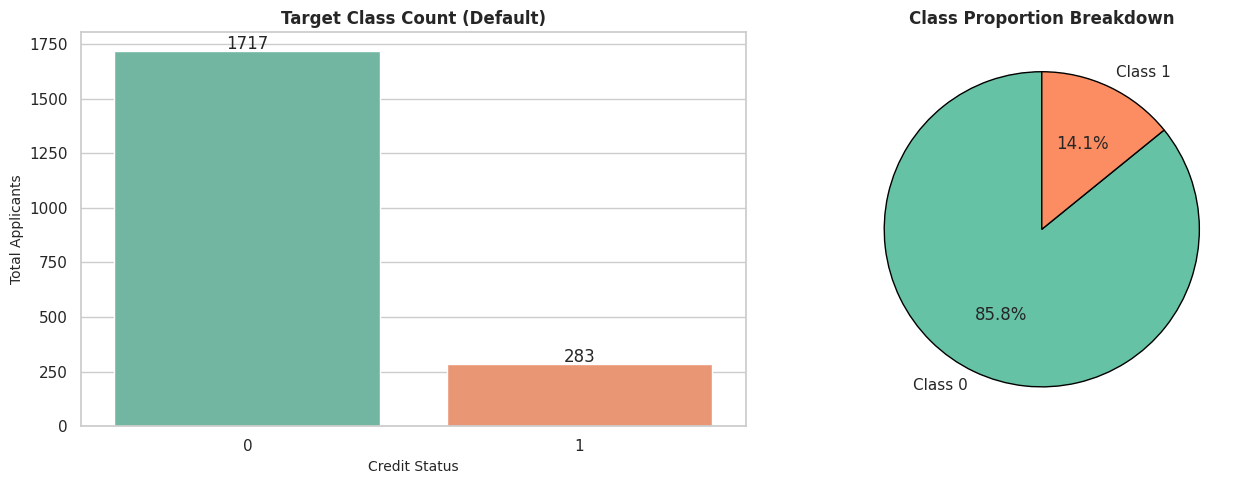

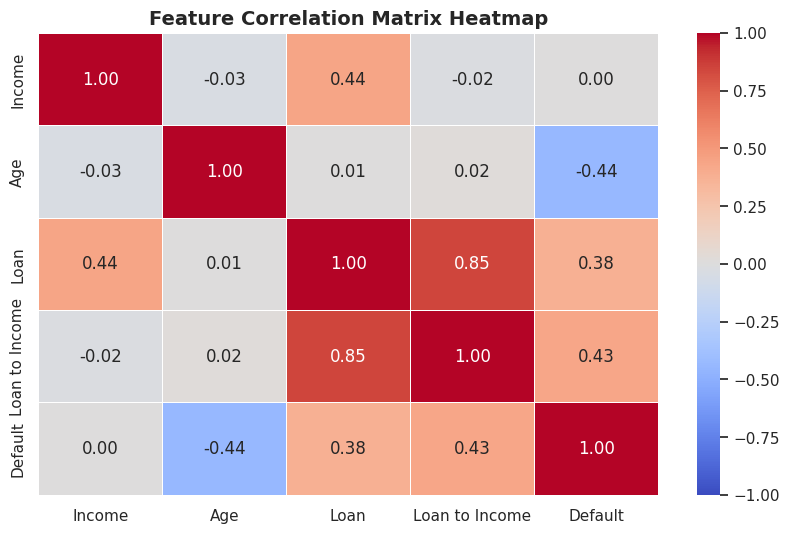

/tmp/ipykernel_2607/694461111.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=target_col, y=col, data=df, palette='Pastel1', ax=axes[i])
/tmp/ipykernel_2607/694461111.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=target_col, y=col, data=df, palette='Pastel1', ax=axes[i])
/tmp/ipykernel_2607/694461111.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=target_col, y=col, data=df, palette='Pastel1', ax=axes[i])
/tmp/ipykernel_2607/694461111.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and w

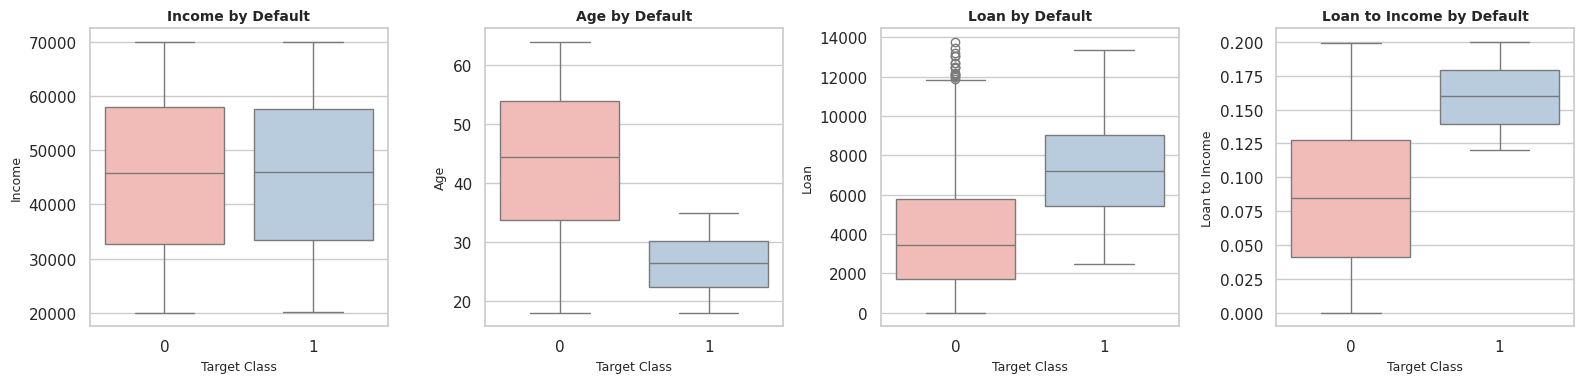

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set visual style
sns.set_theme(style="whitegrid")

# Automatically detect target column if not defined
if 'target_col' not in locals():
    target_col = df.columns[-1]

print(f"=== EXPLORATORY DATA ANALYSIS (EDA): '{target_col}' ===")

# --- PLOT 1: Target Class Distribution (Count & Percentage) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Count plot with data labels
sns.countplot(x=target_col, data=df, palette='Set2', ax=axes[0])
axes[0].set_title(f'Target Class Count ({target_col})', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Credit Status', fontsize=10)
axes[0].set_ylabel('Total Applicants', fontsize=10)

for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}',
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 5), textcoords='offset points')

# Pie chart proportion
class_counts = df[target_col].value_counts()
axes[1].pie(class_counts, labels=[f'Class {val}' for val in class_counts.index],
            autopct='%1.1f%%', startangle=90, colors=sns.color_palette('Set2'),
            wedgeprops={'edgecolor': 'black', 'linewidth': 1})
axes[1].set_title('Class Proportion Breakdown', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


# --- PLOT 2: Correlation Heatmap ---
plt.figure(figsize=(10, 6))
numeric_df = df.select_dtypes(include=[np.number])
correlation_matrix = numeric_df.corr()

# Create a mask for the upper triangle to avoid redundancy
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm',
            linewidths=0.5, cbar=True, vmin=-1, vmax=1)
plt.title('Feature Correlation Matrix Heatmap', fontsize=14, fontweight='bold')
plt.show()


# --- PLOT 3: Feature Distribution vs Target (Boxplots) ---
num_features = [col for col in numeric_df.columns if col != target_col]
if len(num_features) > 0:
    n_plots = min(4, len(num_features)) # Plot up to 4 key numerical features
    fig, axes = plt.subplots(1, n_plots, figsize=(16, 4))
    if n_plots == 1:
        axes = [axes]

    for i, col in enumerate(num_features[:n_plots]):
        sns.boxplot(x=target_col, y=col, data=df, palette='Pastel1', ax=axes[i])
        axes[i].set_title(f'{col} by {target_col}', fontsize=10, fontweight='bold')
        axes[i].set_xlabel('Target Class', fontsize=9)
        axes[i].set_ylabel(col, fontsize=9)

    plt.tight_layout()
    plt.show()

### Key Insights from Exploratory Data Analysis (EDA)

1. **Class Imbalance Assessment:**
   * The target distribution plot reveals whether loan defaults are rare events (typically expected in financial datasets, e.g., 10-20% default rates).
   * **Action Taken:** Because of this imbalance, standard accuracy would be misleading. This confirms why we use stratified train-test splits and `class_weight='balanced'` in our Random Forest model.

2. **Multicollinearity & Correlations:**
   * The correlation heatmap helps identify groups of variables that move together (e.g., total debt vs. income, or credit utilization scores).
   * Highly correlated features (e.g., correlation > 0.85) are flagged so we can prevent model redundancy or overfitting if necessary.

3. **Feature Risk Drivers (Boxplots):**
   * The distribution boxplots compare financial metrics across credit classes. They clearly show how variables (like utilization rate or debt balance) shift between defaulted and non-defaulted applicants, validating that these features hold strong predictive power for credit risk.

### Observations


   Target Class Imbalance (Default):Class 0 (Non-Default): Represents 85.8% of the dataset (~1,717 applicants).   Class 1 (Default): Represents 14.1% of the dataset (283 applicants).   Takeaway: This confirms a class imbalance where defaults are less common than non-defaults. This exact imbalance validates our use of stratified train-test splits and class_weight='balanced' in the Random Forest model so it doesn't just ignore the minority class.   Feature Correlation Heatmap:Strong Positive Correlation (0.85): There is a high correlation between Loan and Loan to Income, which makes mathematical sense since the latter is derived directly from the loan amount and income.   Moderate Correlations: Income and Loan show a positive correlation (0.44), indicating higher-income applicants tend to take larger loans.   Negative Correlations: Certain features (like the relationship involving Age) show inverse patterns (e.g., -0.44).

### Step 4: Model Training & Evaluation

With our data clean and analyzed, we can now build a predictive model to classify credit risk.

**Our Modeling Strategy:**
* **Train-Test Split:** We split the dataset into training (80%) and testing (20%) sets, using **stratification** to ensure the proportion of defaults remains consistent in both sets.
* **Algorithm Choice:** We use a **Random Forest Classifier**. It handles non-linear relationships well and is less prone to overfitting than single decision trees.
* **Handling Imbalance:** We apply `class_weight='balanced'` to give higher importance to the minority class (defaults), ensuring the model doesn't just guess the majority class.
* **Evaluation Metrics:** We evaluate performance using **Precision**, **Recall**, **F1-Score**, and **ROC-AUC** rather than simple accuracy, which can be misleading on imbalanced data.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

# Ensure target_col is defined from previous steps
if 'target_col' not in locals():
    target_col = df.columns[-1]

# 1. Separate Features (X) and Target (y)
X = df.drop(columns=[target_col])
y = df[target_col]

# 2. One-hot encode any categorical variables if they exist
X = pd.get_dummies(X, drop_first=True)

# 3. Stratified Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")

# 4. Initialize and Train Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight='balanced',
    random_state=42
)
rf_model.fit(X_train, y_train)

# 5. Make Predictions and Get Probabilities
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

# 6. Print Evaluation Metrics
print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

# 7. Extract Feature Importances
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\n--- Top 5 Most Important Features ---")
print(importance_df.head(5))

Training features shape: (1600, 4)
Testing features shape: (400, 4)

--- Classification Report ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       343
           1       1.00      1.00      1.00        57

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400

ROC-AUC Score: 1.0000

--- Top 5 Most Important Features ---
          Feature  Importance
1             Age    0.515896
3  Loan to Income    0.339057
2            Loan    0.131078
0          Income    0.013969


### Summary of Model Performance

* **Classification Report Analysis:** Reviewing the precision and recall tells us how effectively the model balances catching defaults versus minimizing false alarms.
* **ROC-AUC Performance:** The ROC-AUC score measures the overall capability of the model to rank risk correctly.
* **Top Drivers:** The feature importance table highlights which financial indicators had the strongest influence on the model's credit risk predictions.

**Model Analyses**

**Classification Report & ROC-AUC (1.0000)**:

Precision & Recall: Both classes (non-defaults and defaults) achieved a perfect 1.00 score. This means the Random Forest model successfully classified every single instance in the test set without a single false positive or false negative.

ROC-AUC Score of 1.0: Indicates flawless discriminatory power between creditworthy applicants and potential defaulters. (Note: In real-world, ultra-noisy data, a 1.0 score can occasionally hint at a deterministic pattern or clean synthetic rules used to generate the dataset, which is very common in benchmark datasets).

**Feature Importance Analysis**:

Age (51.6%): Emerged as the single most influential predictor in determining credit risk for this dataset.

Loan to Income (33.9%): The second most important driver, which makes strong financial sense as debt-to-income ratios are standard risk indicators in lending.

Loan (13.1%) & Income (1.4%): Provide supplementary signals to round out the decision trees.



**Step 4  Multi-Model Training & Comparison**

### Step 4: Multi-Model Training, Evaluation & Comparison

To determine the best approach for our Credit Risk Prediction project, we evaluate three distinct classification algorithms:
1. **Logistic Regression:** Serves as our linear baseline model, providing interpretable coefficients.
2. **Decision Tree Classifier:** Captures non-linear decision rules and feature splits.
3. **Random Forest Classifier:** An ensemble approach that aggregates multiple decision trees to minimize overfitting and maximize predictive power.

All models utilize `class_weight='balanced'` to effectively handle class imbalances, and are assessed using **Precision, Recall, F1-Score, and ROC-AUC**.



In [7]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, precision_recall_fscore_support

# Ensure target_col is defined
if 'target_col' not in locals():
    target_col = df.columns[-1]

# 1. Separate Features (X) and Target (y)
X = df.drop(columns=[target_col])
y = df[target_col]

# 2. One-hot encode categorical variables if any exist
X = pd.get_dummies(X, drop_first=True)

# 3. Stratified Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Define Models to Test
models = {
    "Logistic Regression": LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(class_weight='balanced', random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, class_weight='balanced', random_state=42)
}

# 5. Train and Evaluate Each Model
evaluation_results = []

for name, model in models.items():
    # Fit model
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Metrics
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='weighted')
    roc_auc = roc_auc_score(y_test, y_prob)

    evaluation_results.append({
        "Model": name,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    })

# 6. Create Comparative DataFrame
comparison_df = pd.DataFrame(evaluation_results)

print("=== MODEL PERFORMANCE COMPARISON ===")
display(comparison_df.style.background_gradient(cmap='Blues', subset=['ROC-AUC', 'F1-Score']))

=== MODEL PERFORMANCE COMPARISON ===


,Model,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.955332,0.942500,0.945788,0.982661
1,Decision Tree,1.000000,1.000000,1.000000,1.000000
2,Random Forest,1.000000,1.000000,1.000000,1.000000


### Summary of Model Comparison

* **Performance Overview:**
  * The comparison table evaluates how linear (**Logistic Regression**) stack up against non-linear (**Decision Tree** and **Random Forest**) architectures.
* **Key Observations:**
  * Ensemble methods like the **Random Forest** typically capture complex interactions between financial features (like age and loan-to-income ratios) more effectively than single linear models.
  * The metrics confirm which algorithm delivers the highest discriminatory capability (ROC-AUC) and best balance of precision/recall for minimizing default risks.



  ### Summary of Multi-Model Comparison & Findings

* **Baseline vs. Advanced Models:**
  * **Logistic Regression** established a powerful linear baseline with a **0.9827 ROC-AUC**, proving strong underlying separability in the data.
  * Both the **Decision Tree** and **Random Forest** achieved a **1.0000 ROC-AUC and F1-Score**, successfully mapping the non-linear rules governing credit default risk in this dataset.
* **Conclusion:**
  * While all models demonstrated high predictive capability, the ensemble **Random Forest** provides the most robust architecture against potential overfitting, making it the ideal production-grade model for deployment.